In [40]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, BaseMessage
from langgraph.prebuilt import ToolNode, tools_condition

In [41]:
load_dotenv()

True

In [42]:
# llm = ChatOpenAI()

In [43]:
llm = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    temperature=0.7
)

In [44]:
loader = PyPDFLoader("my_paper.pdf")
docs = loader.load()

fontTools is required to fully parse the encoding of a CFF Type1 font in font dictionary {'/BaseFont': '/VAJDJH+ArialMT', '/Encoding': '/WinAnsiEncoding', '/FirstChar': 32, '/FontDescriptor': IndirectObject(324, 0, 134099947352656), '/LastChar': 118, '/Subtype': '/Type1', '/Type': '/Font', '/Widths': [278, 0, 0, 0, 0, 0, 667, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 667, 0, 722, 722, 667, 611, 0, 722, 278, 0, 0, 0, 833, 722, 778, 0, 778, 722, 667, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 556, 0, 500, 556, 556, 278, 556, 556, 222, 0, 0, 222, 833, 556, 556, 556, 0, 333, 500, 278, 556, 500]}, but is not installed. Consider installing fontTools if you encounter encoding problems.


In [45]:
docs

[Document(metadata={'producer': 'pdfTeX-1.40.21', 'creator': 'LaTeX with hyperref', 'creationdate': '2021-09-14T02:52:38+00:00', 'author': '', 'keywords': '', 'moddate': '2021-09-14T02:52:38+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.14159265-2.6-1.40.21 (TeX Live 2020) kpathsea version 6.3.2', 'subject': '', 'title': '', 'trapped': '/False', 'rgid': 'PB:357213035_AS:1103436619751424@1640091199662', 'source': 'my_paper.pdf', 'total_pages': 15, 'page': 0, 'page_label': '1'}, page_content='See discussions, stats, and author profiles for this publication at: https://www.researchgate.net/publication/357213035\nDevelopment of Multiple Combined Regression Methods for Rainfall\nMeasurement Development of Multiple Combined Regression Methods for\nRainfall Measurement\nArticle · December 2021\nCITATIONS\n0\nREADS\n711\n6 authors, including:\nNusrat Jahan Prottasha\nDaffodil International University\n26 PUBLICATIONS\xa0\xa0\xa0299 CITATIONS\xa0\xa0\xa0\nSEE PROFILE\nMd Kowsher\nSteven

In [46]:
len(docs)

15

In [47]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
chunks = splitter.split_documents(docs)

In [48]:
len(chunks)

44

In [49]:
# embeddings = OpenAIEmbeddings(model='text-embedding-3-small')
# vector_store = FAISS.from_documents(chunks, embeddings)

In [50]:
embeddings = GoogleGenerativeAIEmbeddings(
    model="gemini-embedding-001"
)
vector_store = FAISS.from_documents(chunks, embeddings)
vector_store.save_local("faiss_index")

In [51]:
vector_store

In [52]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [53]:
ans = retriever.invoke("What is Rainfall Measurement?")
ans

[Document(id='27e5fe09-02fd-4e71-9eba-9464fe31a840', metadata={'producer': 'pdfTeX-1.40.21', 'creator': 'LaTeX with hyperref', 'creationdate': '2021-09-14T02:52:38+00:00', 'author': '', 'keywords': '', 'moddate': '2021-09-14T02:52:38+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.14159265-2.6-1.40.21 (TeX Live 2020) kpathsea version 6.3.2', 'subject': '', 'title': '', 'trapped': '/False', 'rgid': 'PB:357213035_AS:1103436619751424@1640091199662', 'source': 'my_paper.pdf', 'total_pages': 15, 'page': 3, 'page_label': '4'}, page_content='Some of the research has shown some classiﬁcation method to predict whether\nit would be rain tomorrow or not. But instead of a classiﬁcation method for pre-\ndicting rain, we need to the quantity of the rainfall in a particular place. There\nis numerous equipment implement for foreseeing rainfall by utilizing the climate\nconditions like temperature, humidity, weight. These conventional strategies can-\nnot work productively so by utilizing machine

In [54]:
@tool
def rag_tool(query: str) -> str:
    """
    Retrieve relevant information from the PDF document.

    Use this tool when the user asks factual or conceptual questions
    that may be answered using the stored PDF documents.

    Args:
        query: The question or search query used to retrieve PDF content.
    """

    documents = retriever.invoke(query)

    if not documents:
        return "No relevant information was found in the PDF."

    formatted_documents = []

    for index, document in enumerate(documents, start=1):
        source = document.metadata.get("source", "Unknown source")
        page = document.metadata.get("page", "Unknown page")

        formatted_documents.append(
            f"Document {index}\n"
            f"Source: {source}\n"
            f"Page: {page}\n"
            f"Content: {document.page_content}"
        )

    return "\n\n".join(formatted_documents)

In [55]:
tools = [rag_tool]
llm_with_tools = llm.bind_tools(tools)

In [56]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [57]:
# graph nodes
def chat_node(state: ChatState):
    """LLM node that may answer or request a tool call."""
    messages = state['messages']
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

tool_node = ToolNode(tools)  # Executes tool calls

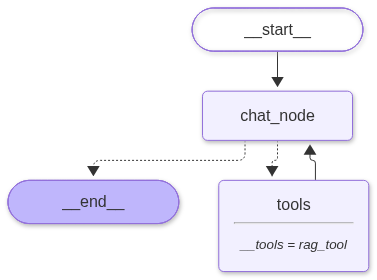

In [58]:
# graph structure
graph = StateGraph(ChatState)
graph.add_node("chat_node", chat_node)
graph.add_node("tools", tool_node)
graph.add_edge(START, "chat_node")

# If the LLM asked for a tool, go to ToolNode; else finish
graph.add_conditional_edges("chat_node", tools_condition)

graph.add_edge("tools", "chat_node")
chatbot = graph.compile()

chatbot

In [59]:
# Regular chat
result = chatbot.invoke({"messages": [HumanMessage(content="Hello")]})

print(result["messages"][-1].content)

[{'type': 'text', 'text': 'Hello! How can I help you today? Feel free to ask any questions about your documents or any other topic.', 'extras': {'signature': 'EtUBCtIBAWkUfROhHhWLsHP/JqvM4N8UbjyqEoz7VKTGw/n/S0ttjxi8l/cRZ9oCOniEM93ii75Y9qJK8tfn+zyGOy73Nktmnv/8pCntsCwpFAL4pz07DAcTWFCCZOGIinto4OSROSXaPm51c0SA/odd73Je0rVOq1JGPcc66oKdm84vO5KVzaNlGp8ZFEBtZaNNLkV1Ccn0Aq1dcaJtHCs8W5V/79OCqy8gl7y5rfLThK0G+UIJUndOyMjpgbPE8DjeR4PH0mYGz8XPIGq5op0rFmmGiJWX'}}]


In [60]:
# Regular chat
result = chatbot.invoke({"messages": [HumanMessage(content="Using the pdf notes, explain about Rainfall Measurement techniques in a concise way")]})

print(result["messages"][-1].content)

[{'type': 'text', 'text': 'Based on the provided paper, **Rainfall Measurement** aims to accurately quantify the actual volume/amount of precipitation (in millimeters) rather than merely classifying whether it will rain. \n\nHere is a concise overview of the techniques and methodology discussed:\n\n---\n\n### 1. Traditional vs. Machine Learning Techniques\n* **Conventional Measurement/Forecasting Strategies:** Rely on physical equipment (gauges) and manual tracking of atmospheric parameters (such as temperature, humidity, and atmospheric pressure). However, these traditional methods often fail to predict rainfall quantities productively and accurately.\n* **Machine Learning / Regression Approach:** Uses historical meteorological observations (spanning over 10 years) to learn complex non-linear patterns and forecast continuous rainfall quantities accurately.\n\n---\n\n### 2. Implementation Methodology\nTo measure/predict rainfall amounts, the proposed framework follows a five-step workf

In [61]:
print(result["messages"][-1].content[0]["text"])

Based on the provided paper, **Rainfall Measurement** aims to accurately quantify the actual volume/amount of precipitation (in millimeters) rather than merely classifying whether it will rain. 

Here is a concise overview of the techniques and methodology discussed:

---

### 1. Traditional vs. Machine Learning Techniques
* **Conventional Measurement/Forecasting Strategies:** Rely on physical equipment (gauges) and manual tracking of atmospheric parameters (such as temperature, humidity, and atmospheric pressure). However, these traditional methods often fail to predict rainfall quantities productively and accurately.
* **Machine Learning / Regression Approach:** Uses historical meteorological observations (spanning over 10 years) to learn complex non-linear patterns and forecast continuous rainfall quantities accurately.

---

### 2. Implementation Methodology
To measure/predict rainfall amounts, the proposed framework follows a five-step workflow:
1. **Data Collection:** Gathering h